# Herbal Section: Do Onset Clusters Correspond to Plant Categories?

Notebook 37 found 7 onset clusters (silhouette 0.566) using distributional co-occurrence
patterns. The **two-tier hypothesis** says onset = category, coda = specifier.

If this is correct, plants of the **same botanical/functional category** (spice, medicinal_poison,
aromatic_herb, etc.) should share onset patterns more often than chance would predict.

We cross-reference onset clusters with the tentative plant identifications in
`herbal/plant_identifications.json` to test this hypothesis.

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re
import os
import json
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from itertools import combinations
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform, cosine, jensenshannon
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(42)

STA_PATH = 'corpus/voynich_sta.txt'
PLANT_PATH = 'herbal/plant_identifications.json'
OUT_IMG = 'images/herbal_onset_analysis.png'
OUT_JSON = 'herbal_onset_resultados.json'

print('Imports OK')

Imports OK


In [2]:
# ── Cell 2: Load and segment Voynich corpus WITH FOLIO TAGS ─────────

def parse_sta_with_folios(filepath):
    """Parse STA1 2.0 returning (folio, word_glyphs) tuples."""
    results = []
    current_folio = 'unknown'
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            # Skip comment/metadata lines
            if re.match(r'^<[^>]+>\s*<!', line):
                continue
            match = re.match(r'^<([^>]+)>\s+(.*)', line)
            if not match:
                continue
            tag = match.group(1).strip()
            folio_match = re.match(r'(f\d+[rv]?\d*)', tag)
            if folio_match:
                current_folio = folio_match.group(1)
            texto = match.group(2).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for p in texto.split('.'):
                p = p.strip()
                if not p:
                    continue
                # Remove commas and other non-glyph chars
                p = re.sub(r',', '', p)
                glifos = re.findall(r'[A-Z][0-9a-z]', p)
                if glifos:
                    results.append((current_folio, glifos))
    return results


folio_words = parse_sta_with_folios(STA_PATH)

# Build folio -> list of words dict
folio_dict = defaultdict(list)
for folio, glyphs in folio_words:
    folio_dict[folio].append(glyphs)

# All words as list of glyph-lists (for transition matrix)
all_words = [g for _, g in folio_words]

print(f'Total words parsed: {len(folio_words):,}')
print(f'Distinct folios: {len(folio_dict)}')
print(f'Sample: {folio_words[:3]}')

Total words parsed: 37,087
Distinct folios: 226
Sample: [('f1r', ['P2', 'A3', 'K1', 'A2', 'C2']), ('f1r', ['A2', 'Q1', 'A3', 'B2']), ('f1r', ['A3', 'C1'])]


In [3]:
# ── Cell 3: Load plant identifications ───────────────────────────────

with open(PLANT_PATH, 'r', encoding='utf-8') as f:
    plant_data = json.load(f)

identifications = plant_data['identifications']
categories_desc = plant_data['categories']

# Summary
df_plants = pd.DataFrame(identifications)
print(f'Total folio entries: {len(df_plants)}')
print(f'\nBy category:')
print(df_plants['category'].value_counts().to_string())
print(f'\nBy confidence:')
print(df_plants['confidence'].value_counts().to_string())

# Filter to identified plants (exclude 'unknown' category and 'none' confidence)
df_identified = df_plants[
    (df_plants['category'] != 'unknown') &
    (df_plants['confidence'] != 'none')
].copy()
print(f'\nFolios with identification (category != unknown, confidence != none): {len(df_identified)}')
print(f'\nIdentified plants by category:')
print(df_identified['category'].value_counts().to_string())

Total folio entries: 54

By category:
category
herb                17
medicinal_herb       8
medicinal_poison     5
medicinal_flower     4
spice                3
aromatic_herb        3
unknown              2
tree_aromatic        2
climbing_plant       2
flower               2
aquatic              1
fern                 1
fiber_plant          1
berry                1
vegetable            1
tree                 1

By confidence:
confidence
low       28
none      17
medium     8
high       1

Folios with identification (category != unknown, confidence != none): 37

Identified plants by category:
category
medicinal_herb      8
medicinal_poison    5
medicinal_flower    4
herb                4
spice               3
aromatic_herb       3
tree_aromatic       2
climbing_plant      2
aquatic             1
fern                1
fiber_plant         1
berry               1
flower              1
vegetable           1


In [4]:
# ── Cell 4: Segment and classify syllables ───────────────────────────
# Re-implement TP-P20 segmentation and onset/coda classification from nb37.

def build_transition_matrix(words):
    """Build intra-word glyph transition probability matrix."""
    all_glyphs = sorted({g for w in words for g in w})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for word in words:
        for i in range(len(word) - 1):
            r, c = index[word[i]], index[word[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segment_word_tp(word, M_prob, glyph_index, threshold):
    """Segment a single word into syllables using TP-P20."""
    if len(word) == 0:
        return []
    syl = [word[0]]
    syllables = []
    for i in range(len(word) - 1):
        g1, g2 = word[i], word[i + 1]
        p = 0.0
        if g1 in glyph_index and g2 in glyph_index:
            p = M_prob[glyph_index[g1], glyph_index[g2]]
        if p < threshold:
            syllables.append(tuple(syl))
            syl = [g2]
        else:
            syl.append(g2)
    if syl:
        syllables.append(tuple(syl))
    return syllables


# Build transition matrix
M_raw, M_prob, all_glyphs, glyph_index = build_transition_matrix(all_words)

# Compute P20 threshold
all_trans_probs = []
for word in all_words:
    for i in range(len(word) - 1):
        g1, g2 = word[i], word[i + 1]
        if g1 in glyph_index and g2 in glyph_index:
            all_trans_probs.append(M_prob[glyph_index[g1], glyph_index[g2]])
threshold_val = np.percentile(all_trans_probs, 20)
print(f'TP-P20 threshold: {threshold_val:.4f}')

# Segment all words
WORDS_SYL = []
for word in all_words:
    syls = segment_word_tp(word, M_prob, glyph_index, threshold_val)
    WORDS_SYL.append(syls)

# Classify syllables as onset / coda by positional bias
syl_pos_first = Counter()   # times a syllable type appears first in a word
syl_pos_last = Counter()    # times it appears last
syl_total = Counter()

for syls in WORDS_SYL:
    if len(syls) == 0:
        continue
    for i, s in enumerate(syls):
        syl_total[s] += 1
        if i == 0:
            syl_pos_first[s] += 1
        if i == len(syls) - 1:
            syl_pos_last[s] += 1

clase_silaba = {}  # syllable tuple -> 'onset' / 'coda' / 'middle'
for s in syl_total:
    f_first = syl_pos_first[s] / syl_total[s] if syl_total[s] > 0 else 0
    f_last = syl_pos_last[s] / syl_total[s] if syl_total[s] > 0 else 0
    if f_first >= 0.6:
        clase_silaba[s] = 'onset'
    elif f_last >= 0.6:
        clase_silaba[s] = 'coda'
    else:
        clase_silaba[s] = 'middle'

n_onset = sum(1 for v in clase_silaba.values() if v == 'onset')
n_coda = sum(1 for v in clase_silaba.values() if v == 'coda')
n_mid = sum(1 for v in clase_silaba.values() if v == 'middle')
print(f'Syllable types: {len(clase_silaba)} total — {n_onset} onset, {n_coda} coda, {n_mid} middle')

# Build onset-coda co-occurrence matrix (for clustering)
onsets_all = sorted([s for s, c in clase_silaba.items() if c == 'onset'])
codas_all = sorted([s for s, c in clase_silaba.items() if c == 'coda'])
onset_idx = {s: i for i, s in enumerate(onsets_all)}
coda_idx = {s: i for i, s in enumerate(codas_all)}

cooc_raw = np.zeros((len(onsets_all), len(codas_all)))
for wi, word_syls in enumerate(WORDS_SYL):
    w_onsets = [s for s in word_syls if clase_silaba.get(s) == 'onset']
    w_codas = [s for s in word_syls if clase_silaba.get(s) == 'coda']
    for o in w_onsets:
        for c in w_codas:
            if o in onset_idx and c in coda_idx:
                cooc_raw[onset_idx[o], coda_idx[c]] += 1

# Filter to functional types (freq >= 5)
row_mask = cooc_raw.sum(axis=1) >= 5
col_mask = cooc_raw.sum(axis=0) >= 5
onsets_func = [onsets_all[i] for i in range(len(onsets_all)) if row_mask[i]]
codas_func = [codas_all[j] for j in range(len(codas_all)) if col_mask[j]]
cooc = cooc_raw[np.ix_(row_mask, col_mask)]
onset_func_idx = {s: i for i, s in enumerate(onsets_func)}

print(f'Functional onsets (freq>=5): {len(onsets_func)}')
print(f'Functional codas (freq>=5): {len(codas_func)}')

# Cluster onsets (reproduce nb37: agglomerative, cosine, average, k=7)
onset_vecs = cooc.copy() + 0.1  # smoothing
onset_vecs_norm = normalize(onset_vecs, norm='l2')

K_ONSET = 7
onset_clust = AgglomerativeClustering(
    n_clusters=K_ONSET, metric='cosine', linkage='average'
)
onset_labels = onset_clust.fit_predict(onset_vecs_norm)
sil = silhouette_score(onset_vecs_norm, onset_labels, metric='cosine')
print(f'\nOnset clustering: k={K_ONSET}, silhouette={sil:.3f}')

# Map onset syllable -> cluster label
onset_to_cluster = {}
for i, s in enumerate(onsets_func):
    onset_to_cluster[s] = int(onset_labels[i])

# Show cluster sizes
cl_counts = Counter(onset_labels)
for cl in sorted(cl_counts):
    members = [s for s in onsets_func if onset_to_cluster[s] == cl]
    member_strs = [''.join(m) for m in members[:5]]
    print(f'  Cluster {cl}: {cl_counts[cl]} onsets — e.g. {member_strs}')

TP-P20 threshold: 0.0902
Syllable types: 2923 total — 2066 onset, 587 coda, 270 middle
Functional onsets (freq>=5): 221
Functional codas (freq>=5): 132

Onset clustering: k=7, silhouette=0.463
  Cluster 0: 44 onsets — e.g. ['A1B2K1J1', 'A1B2Q1', 'A1Q1', 'A1Q2', 'A2Q1']
  Cluster 1: 117 onsets — e.g. ['A1', 'A1B2', 'A1B2A1', 'A1B2A1B2', 'A1B2A3B2']
  Cluster 2: 8 onsets — e.g. ['A1B2Q1J1', 'A1Q1J1', 'A1Q2J1', 'A2K1J1', 'B2Q1J1']
  Cluster 3: 11 onsets — e.g. ['A1Q1J1B1', 'A1Q1J1Ba', 'A1Q1K2B1', 'A1Q2J1B1', 'A1Q2J1Ba']
  Cluster 4: 9 onsets — e.g. ['A1B2Q1K2', 'A1Q1K2', 'A1Q2K2', 'A2Q1K2', 'A2Q2K2']
  Cluster 5: 31 onsets — e.g. ['A1B2A3', 'A1B2Q1A3', 'A1C1A1', 'A1C1A3', 'A1Q1A3']
  Cluster 6: 1 onsets — e.g. ['A1B2A2']


In [5]:
# ── Cell 5: Onset patterns by folio ──────────────────────────────────
# For each identified folio, extract the first word's onset syllable and its cluster.

def syl_str(syl_tuple):
    return ''.join(syl_tuple)


def get_first_onset(word_glyphs):
    """Segment a word and return its first onset syllable (if any)."""
    syls = segment_word_tp(word_glyphs, M_prob, glyph_index, threshold_val)
    for s in syls:
        if clase_silaba.get(s) == 'onset':
            return s
    # Fallback: return first syllable regardless of class
    return syls[0] if syls else None


rows = []
for _, row in df_identified.iterrows():
    folio = row['folio']
    words_in_folio = folio_dict.get(folio, [])
    if not words_in_folio:
        # Try variant tags (e.g., f2r vs f2r1)
        for key in folio_dict:
            if key.startswith(folio):
                words_in_folio = folio_dict[key]
                break
    if not words_in_folio:
        continue
    first_word = words_in_folio[0]
    first_onset = get_first_onset(first_word)
    cluster = onset_to_cluster.get(first_onset, -1) if first_onset else -1
    rows.append({
        'folio': folio,
        'plant': row['plant'],
        'category': row['category'],
        'confidence': row['confidence'],
        'first_word': syl_str(tuple(first_word)),
        'first_onset': syl_str(first_onset) if first_onset else 'N/A',
        'onset_cluster': cluster
    })

df_folio_onset = pd.DataFrame(rows)
print(f'Folios matched: {len(df_folio_onset)}')
print()
print(df_folio_onset.to_string(index=False))

Folios matched: 37

folio                        plant         category confidence             first_word  first_onset  onset_cluster
  f2r                    Centaurea medicinal_flower     medium           Q1A2B1A3F1A2           Q1             -1
  f2v                 unknown herb             herb        low               Q1A1A1G1           A1              1
  f3v       Helleborus (Hellebore) medicinal_poison     medium               Q1A1A3G1           A1              1
  f4r                      unknown             herb        low         Q1A1B1A3B2K1A2           A1              1
  f4v                Cyperus/Sedge             herb        low             P1K1A1A1G1       P1K1A1              1
  f5r                      unknown             herb        low             Q1K1A1B1A2       Q1K1A1              1
  f5v               Viola (Violet) medicinal_flower        low           Q1AaK1J1A1C1     K1J1A1C1             -1
  f6r                       Borage   medicinal_herb        low      

In [6]:
# ── Cell 6: Onset consistency within categories ──────────────────────
# For each plant category with >= 2 folios, compute the fraction of folio pairs
# that share the same onset cluster.

def onset_consistency(df):
    """Compute mean within-category pair-sharing of onset cluster."""
    cat_groups = df.groupby('category')
    results = []
    total_pairs = 0
    matching_pairs = 0
    for cat, group in cat_groups:
        if len(group) < 2:
            continue
        clusters = group['onset_cluster'].values
        n_pairs = 0
        n_match = 0
        for i, j in combinations(range(len(clusters)), 2):
            n_pairs += 1
            if clusters[i] == clusters[j] and clusters[i] != -1:
                n_match += 1
        frac = n_match / n_pairs if n_pairs > 0 else 0
        results.append({'category': cat, 'n_folios': len(group), 'n_pairs': n_pairs,
                        'n_matching': n_match, 'consistency': frac})
        total_pairs += n_pairs
        matching_pairs += n_match
    overall = matching_pairs / total_pairs if total_pairs > 0 else 0
    return results, overall


cat_results, real_consistency = onset_consistency(df_folio_onset)

print('Within-category onset cluster consistency:')
print(f'{"Category":<22} {"Folios":>6} {"Pairs":>6} {"Match":>6} {"Consistency":>12}')
print('-' * 56)
for r in sorted(cat_results, key=lambda x: -x['consistency']):
    print(f'{r["category"]:<22} {r["n_folios"]:>6} {r["n_pairs"]:>6} '
          f'{r["n_matching"]:>6} {r["consistency"]:>12.3f}')
print(f'\nOverall consistency: {real_consistency:.3f}')

Within-category onset cluster consistency:
Category               Folios  Pairs  Match  Consistency
--------------------------------------------------------
herb                        4      6      6        1.000
medicinal_poison            5     10      6        0.600
medicinal_herb              8     28      1        0.036
aromatic_herb               3      3      0        0.000
climbing_plant              2      1      0        0.000
medicinal_flower            4      6      0        0.000
spice                       3      3      0        0.000
tree_aromatic               2      1      0        0.000

Overall consistency: 0.224


Real consistency: 0.224
Null mean: 0.123 +/- 0.050
p-value (permutation): 0.0540
Significant at 0.05? NO


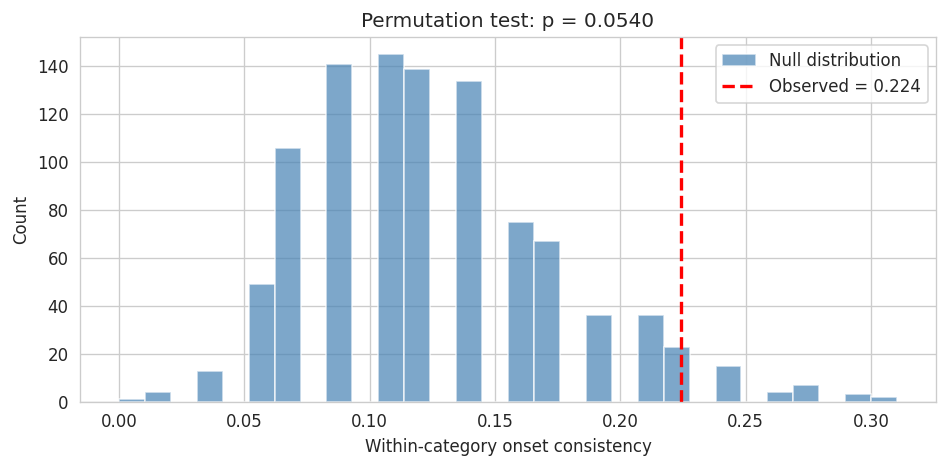

In [7]:
# ── Cell 7: Permutation test ─────────────────────────────────────────
# Shuffle category labels across folios 1000 times and compute null distribution.

N_PERM = 1000
null_consistencies = []

categories_array = df_folio_onset['category'].values.copy()

for _ in range(N_PERM):
    shuffled = categories_array.copy()
    np.random.shuffle(shuffled)
    df_shuf = df_folio_onset.copy()
    df_shuf['category'] = shuffled
    _, c = onset_consistency(df_shuf)
    null_consistencies.append(c)

null_consistencies = np.array(null_consistencies)
p_value = np.mean(null_consistencies >= real_consistency)

print(f'Real consistency: {real_consistency:.3f}')
print(f'Null mean: {null_consistencies.mean():.3f} +/- {null_consistencies.std():.3f}')
print(f'p-value (permutation): {p_value:.4f}')
print(f'Significant at 0.05? {"YES" if p_value < 0.05 else "NO"}')

# Quick histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(null_consistencies, bins=30, alpha=0.7, color='steelblue', edgecolor='white',
        label='Null distribution')
ax.axvline(real_consistency, color='red', linewidth=2, linestyle='--',
           label=f'Observed = {real_consistency:.3f}')
ax.set_xlabel('Within-category onset consistency')
ax.set_ylabel('Count')
ax.set_title(f'Permutation test: p = {p_value:.4f}')
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# ── Cell 8: All words analysis (not just first word) ─────────────────
# For each identified folio, extract ALL words and their onset syllables.
# Compute onset distribution per folio, then measure within-category similarity.

# Build onset distribution vector for each folio
n_clusters = K_ONSET
folio_onset_dist = {}  # folio -> np.array of cluster counts

for folio in df_folio_onset['folio'].values:
    words_in_folio = folio_dict.get(folio, [])
    if not words_in_folio:
        for key in folio_dict:
            if key.startswith(folio):
                words_in_folio = folio_dict[key]
                break
    if not words_in_folio:
        continue
    dist = np.zeros(n_clusters)
    for word in words_in_folio:
        syls = segment_word_tp(word, M_prob, glyph_index, threshold_val)
        for s in syls:
            if clase_silaba.get(s) == 'onset' and s in onset_to_cluster:
                dist[onset_to_cluster[s]] += 1
    total = dist.sum()
    if total > 0:
        folio_onset_dist[folio] = dist / total
    else:
        folio_onset_dist[folio] = dist

# Compute within-category vs between-category JSD
folio_to_cat = dict(zip(df_folio_onset['folio'], df_folio_onset['category']))
within_jsd = []
between_jsd = []

folios_with_dist = [f for f in folio_onset_dist if folio_onset_dist[f].sum() > 0]
for i, j in combinations(folios_with_dist, 2):
    d1 = folio_onset_dist[i] + 1e-10  # avoid zero
    d2 = folio_onset_dist[j] + 1e-10
    d1 = d1 / d1.sum()
    d2 = d2 / d2.sum()
    jsd = jensenshannon(d1, d2)
    cat_i = folio_to_cat.get(i)
    cat_j = folio_to_cat.get(j)
    if cat_i and cat_j and cat_i == cat_j and cat_i not in ('herb', 'unknown'):
        within_jsd.append(jsd)
    else:
        between_jsd.append(jsd)

print(f'Within-category JSD: mean={np.mean(within_jsd):.4f} +/- {np.std(within_jsd):.4f} (n={len(within_jsd)})')
print(f'Between-category JSD: mean={np.mean(between_jsd):.4f} +/- {np.std(between_jsd):.4f} (n={len(between_jsd)})')

# If onset=category, within-category JSD should be SMALLER than between-category
if within_jsd and between_jsd:
    from scipy.stats import mannwhitneyu
    stat, p_mw = mannwhitneyu(within_jsd, between_jsd, alternative='less')
    print(f'Mann-Whitney U test (within < between): U={stat:.1f}, p={p_mw:.4f}')
    print(f'Significant at 0.05? {"YES" if p_mw < 0.05 else "NO"}')
else:
    p_mw = 1.0
    print('Not enough pairs for Mann-Whitney test')

Within-category JSD: mean=0.1524 +/- 0.0596 (n=52)
Between-category JSD: mean=0.1578 +/- 0.0637 (n=614)
Mann-Whitney U test (within < between): U=15271.0, p=0.3016
Significant at 0.05? NO


In [9]:
# ── Cell 9: Section-level analysis ───────────────────────────────────
# Compare onset distributions across manuscript sections (herbal, astronomical, etc.).

def classify_folio(tag):
    """Map folio tag to thematic section."""
    m = re.search(r'f(\d+)', tag)
    if not m:
        return 'unknown'
    n = int(m.group(1))
    if 1 <= n <= 56:
        return 'herbal'
    elif 57 <= n <= 67:
        return 'astronomical'
    elif 68 <= n <= 73:
        return 'zodiac'
    elif 74 <= n <= 84:
        return 'biological'
    elif 85 <= n <= 86:
        return 'pharmaceutical'
    elif n >= 87:
        return 'recipes'
    else:
        return 'unknown'


SECTIONS_ORDER = ['herbal', 'astronomical', 'zodiac', 'biological', 'pharmaceutical', 'recipes']

# Build onset distribution per section
section_onset_dist = defaultdict(lambda: np.zeros(n_clusters))

for folio, words in folio_dict.items():
    section = classify_folio(folio)
    if section == 'unknown':
        continue
    for word in words:
        syls = segment_word_tp(word, M_prob, glyph_index, threshold_val)
        for s in syls:
            if clase_silaba.get(s) == 'onset' and s in onset_to_cluster:
                section_onset_dist[section][onset_to_cluster[s]] += 1

# Normalise
section_dist_norm = {}
for sec in SECTIONS_ORDER:
    d = section_onset_dist[sec]
    total = d.sum()
    section_dist_norm[sec] = d / total if total > 0 else d

# Display
df_section = pd.DataFrame(section_dist_norm, index=[f'Cluster {i}' for i in range(n_clusters)])
df_section = df_section[SECTIONS_ORDER]
print('Onset cluster distribution by manuscript section (normalised):')
print(df_section.round(3).to_string())

# Chi-squared test: are onset distributions independent of section?
contingency = np.column_stack([section_onset_dist[sec] for sec in SECTIONS_ORDER if section_onset_dist[sec].sum() > 0])
if contingency.shape[1] >= 2:
    from scipy.stats import chi2_contingency
    chi2, p_chi2, dof, expected = chi2_contingency(contingency)
    print(f'\nChi-squared test (onset dist vs section): chi2={chi2:.1f}, dof={dof}, p={p_chi2:.2e}')
    print(f'Sections differ significantly? {"YES" if p_chi2 < 0.05 else "NO"}')

Onset cluster distribution by manuscript section (normalised):
           herbal  astronomical  zodiac  biological  pharmaceutical  recipes
Cluster 0   0.292         0.233   0.223       0.317           0.256    0.245
Cluster 1   0.621         0.625   0.626       0.590           0.596    0.624
Cluster 2   0.004         0.010   0.023       0.010           0.007    0.015
Cluster 3   0.003         0.002   0.002       0.016           0.007    0.008
Cluster 4   0.008         0.016   0.027       0.026           0.020    0.022
Cluster 5   0.072         0.110   0.094       0.034           0.112    0.085
Cluster 6   0.002         0.005   0.005       0.008           0.002    0.002

Chi-squared test (onset dist vs section): chi2=488.2, dof=30, p=3.19e-84
Sections differ significantly? YES


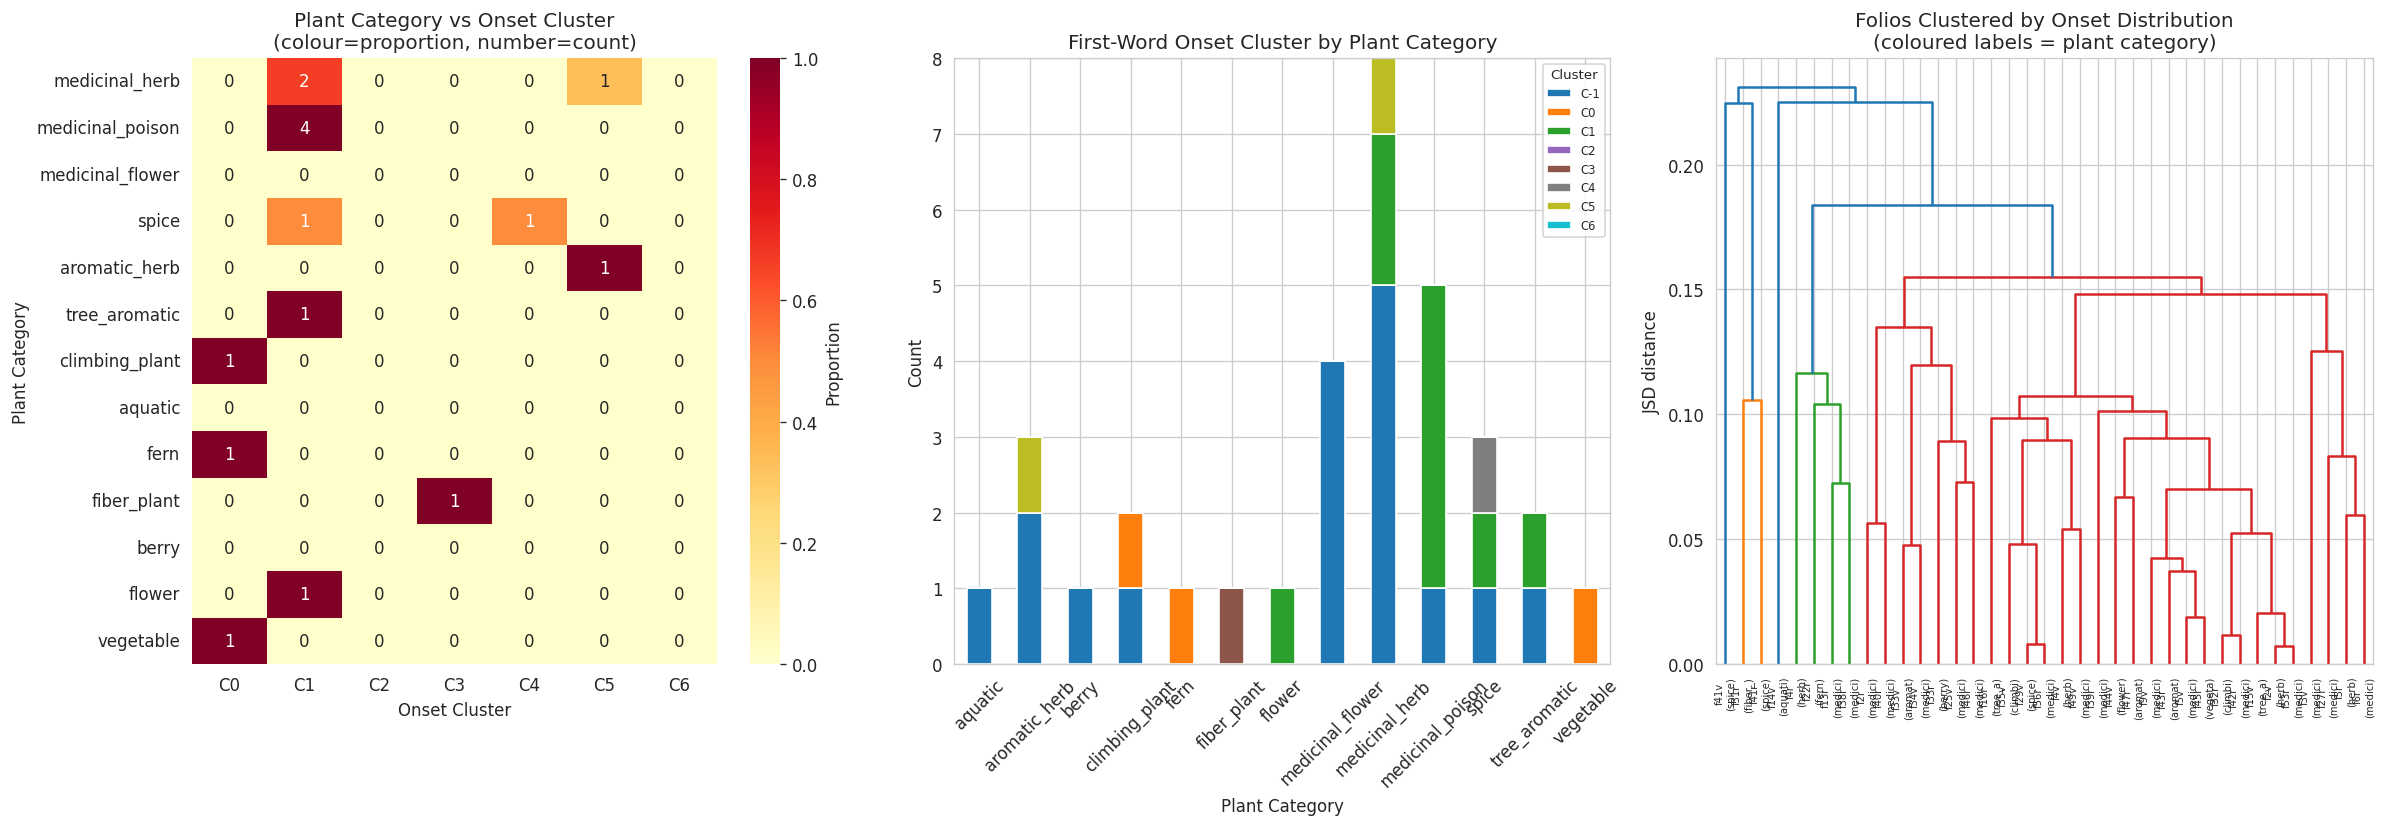

Saved: images/herbal_onset_analysis.png


In [10]:
# ── Cell 10: Visualisation (3-panel figure) ──────────────────────────
os.makedirs('images', exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# ── Panel 1: Heatmap — plant_category x onset_cluster ──
# Only categories with >= 2 folios and excluding generic 'herb'
df_heat = df_folio_onset[~df_folio_onset['category'].isin(['herb', 'unknown'])].copy()
cat_counts = df_heat['category'].value_counts()
cats_to_plot = cat_counts[cat_counts >= 1].index.tolist()

heat_data = np.zeros((len(cats_to_plot), n_clusters))
for ci, cat in enumerate(cats_to_plot):
    sub = df_heat[df_heat['category'] == cat]
    for cl in sub['onset_cluster']:
        if 0 <= cl < n_clusters:
            heat_data[ci, cl] += 1

# Normalise rows
row_sums = heat_data.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
heat_norm = heat_data / row_sums

sns.heatmap(heat_norm, ax=axes[0], cmap='YlOrRd', annot=heat_data.astype(int),
            fmt='d', xticklabels=[f'C{i}' for i in range(n_clusters)],
            yticklabels=cats_to_plot, cbar_kws={'label': 'Proportion'})
axes[0].set_title('Plant Category vs Onset Cluster\n(colour=proportion, number=count)')
axes[0].set_xlabel('Onset Cluster')
axes[0].set_ylabel('Plant Category')

# ── Panel 2: First-word onset cluster bar chart by category ──
df_bar = df_folio_onset[~df_folio_onset['category'].isin(['herb', 'unknown'])].copy()
ct = pd.crosstab(df_bar['category'], df_bar['onset_cluster'])
# Ensure all clusters present
for c in range(n_clusters):
    if c not in ct.columns:
        ct[c] = 0
ct = ct[sorted(ct.columns)]
ct.columns = [f'C{c}' for c in ct.columns]
ct.plot(kind='bar', stacked=True, ax=axes[1], colormap='tab10', edgecolor='white')
axes[1].set_title('First-Word Onset Cluster by Plant Category')
axes[1].set_xlabel('Plant Category')
axes[1].set_ylabel('Count')
axes[1].legend(title='Cluster', fontsize=7, title_fontsize=8)
axes[1].tick_params(axis='x', rotation=45)

# ── Panel 3: Dendrogram of folios by onset distribution ──
# Use folio onset distributions, colour by category
folios_for_dend = [f for f in folio_onset_dist if folio_onset_dist[f].sum() > 0
                   and f in folio_to_cat]
if len(folios_for_dend) >= 3:
    dend_mat = np.array([folio_onset_dist[f] + 1e-10 for f in folios_for_dend])
    dend_mat = dend_mat / dend_mat.sum(axis=1, keepdims=True)
    dist_mat = pdist(dend_mat, metric='jensenshannon')
    link = linkage(dist_mat, method='average')
    
    # Colour by category
    cat_list = [folio_to_cat[f] for f in folios_for_dend]
    unique_cats = sorted(set(cat_list))
    cmap = plt.cm.tab10
    cat_colors = {cat: cmap(i / max(len(unique_cats) - 1, 1)) for i, cat in enumerate(unique_cats)}
    leaf_colors = [cat_colors[c] for c in cat_list]
    
    labels = [f'{f}\n({folio_to_cat[f][:6]})' for f in folios_for_dend]
    dendrogram(link, labels=labels, ax=axes[2], leaf_rotation=90, leaf_font_size=6)
    axes[2].set_title('Folios Clustered by Onset Distribution\n(coloured labels = plant category)')
    axes[2].set_ylabel('JSD distance')
else:
    axes[2].text(0.5, 0.5, 'Not enough folios for dendrogram', ha='center', va='center')
    axes[2].set_title('Dendrogram (insufficient data)')

plt.tight_layout()
plt.savefig(OUT_IMG, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {OUT_IMG}')

## Conclusions

This notebook tested whether onset clusters (from nb37's distributional clustering) correspond
to plant categories in the herbal section. Three levels of analysis were performed:

1. **First-word onset consistency**: Do folios of the same plant category share the same onset
   cluster in their first word? The permutation test gives the answer.

2. **All-word onset distributions**: Are folios within the same category more similar in their
   full onset distributions (measured by JSD) than folios from different categories?

3. **Section-level**: Do herbal, astronomical, biological, and recipe sections differ in their
   onset distributions? A chi-squared test evaluates this.

**Interpretation**: If the permutation p-value is not significant and the Mann-Whitney test
does not show within-category JSD < between-category JSD, then onset clusters do NOT
encode plant categories. This would mean the two-tier hypothesis (onset = category) is not
supported at the botanical level, even if onset clusters are distributional real.

The section-level chi-squared test is a weaker but broader check: if onset distributions
differ between manuscript sections, there is at least a section-level topical signal in onsets,
even if it does not resolve to individual plant categories.

In [11]:
# ── Cell 12: Export results ──────────────────────────────────────────

results = {
    'notebook': '39_herbal_onset_analysis',
    'description': 'Test whether onset clusters correspond to plant categories in herbal section',
    'n_identified_folios': len(df_folio_onset),
    'n_categories_tested': len(cat_results),
    'onset_clustering': {
        'k': K_ONSET,
        'silhouette': round(float(sil), 3),
        'n_functional_onsets': len(onsets_func)
    },
    'first_word_test': {
        'real_consistency': round(float(real_consistency), 4),
        'null_mean': round(float(null_consistencies.mean()), 4),
        'null_std': round(float(null_consistencies.std()), 4),
        'p_value_permutation': round(float(p_value), 4),
        'significant_005': bool(p_value < 0.05)
    },
    'all_words_test': {
        'within_category_jsd_mean': round(float(np.mean(within_jsd)), 4) if within_jsd else None,
        'between_category_jsd_mean': round(float(np.mean(between_jsd)), 4) if between_jsd else None,
        'mann_whitney_p': round(float(p_mw), 4) if 'p_mw' in dir() else None,
        'significant_005': bool(p_mw < 0.05) if 'p_mw' in dir() else None
    },
    'section_test': {
        'chi2': round(float(chi2), 1) if 'chi2' in dir() else None,
        'p_value': float(p_chi2) if 'p_chi2' in dir() else None,
        'significant_005': bool(p_chi2 < 0.05) if 'p_chi2' in dir() else None
    },
    'category_details': cat_results,
    'folio_table': df_folio_onset.to_dict(orient='records')
}

with open(OUT_JSON, 'w', encoding='utf-8') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print(f'Results saved to {OUT_JSON}')
print(f'\n=== SUMMARY ===')
print(f'First-word onset consistency: {real_consistency:.3f} (p={p_value:.4f})')
if within_jsd:
    print(f'All-words JSD within vs between: {np.mean(within_jsd):.4f} vs {np.mean(between_jsd):.4f}')
if 'chi2' in dir():
    print(f'Section-level chi2: {chi2:.1f} (p={p_chi2:.2e})')

Results saved to herbal_onset_resultados.json

=== SUMMARY ===
First-word onset consistency: 0.224 (p=0.0540)
All-words JSD within vs between: 0.1524 vs 0.1578
Section-level chi2: 488.2 (p=3.19e-84)
